### 未来可期：RAG技术的进化之路
---
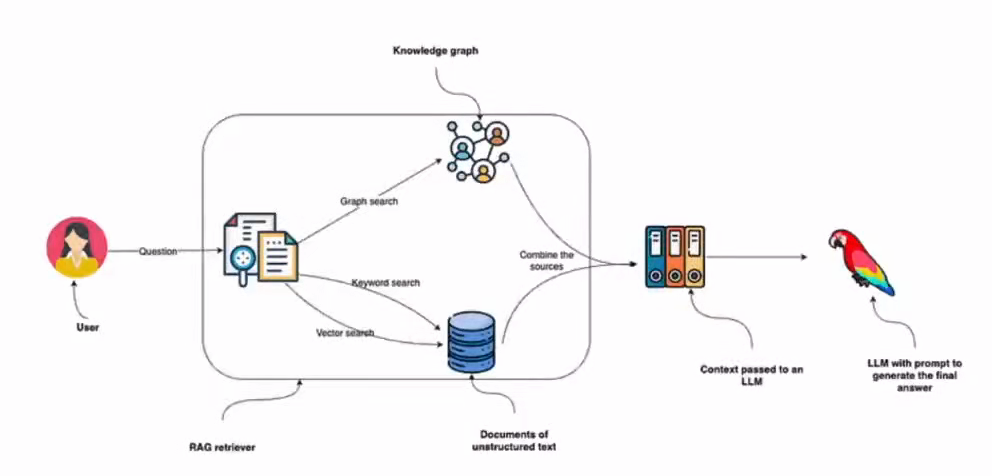

1. Graph RAG
    * 利用图结构存储和检索知识
    * 知识图谱增强
    * 复杂关系推理
    * 多维度信息关联
2. Hybrid RAG
    * 结合多种检索方式
3. Multi-Vector RAG
    * 对同一文档创建多个向量表示
4. Recursive RAG
    * 递归式检索和生成

### Graph_RAG
---
使用知识图谱来增强检索

数据准备

In [11]:
! pip install -qU graph_rag_example_helpers

下载测试文档

In [12]:
from graph_rag_example_helpers.datasets.animals import fetch_documents

animals = fetch_documents()

In [13]:
! pip install "langchain-graph-retriever[chroma]"

简单处理下数据

In [13]:
for doc in animals:
    keys_to_delete = []
    for key, value in doc.metadata.items():
        if isinstance(value, dict):
            keys_to_delete.append(key)

    for key in keys_to_delete:
        del doc.metadata[key]

print(animals)

[Document(id='aardvark', metadata={'type': 'mammal', 'number_of_legs': 4, 'keywords': ['burrowing', 'nocturnal', 'ants', 'savanna'], 'habitat': 'savanna', 'tags': [{'a': 5, 'b': 7}, {'a': 8, 'b': 10}]}, page_content='the aardvark is a nocturnal mammal known for its burrowing habits and long snout used to sniff out ants.'), Document(id='albatross', metadata={'type': 'bird', 'number_of_legs': 2, 'keywords': ['seabird', 'wingspan', 'ocean'], 'habitat': 'marine', 'tags': [{'a': 5, 'b': 8}, {'a': 8, 'b': 10}]}, page_content='the albatross is a large seabird with the longest wingspan of any bird, allowing it to glide effortlessly over oceans.'), Document(id='alligator', metadata={'type': 'reptile', 'number_of_legs': 4, 'keywords': ['reptile', 'jaws', 'wetlands'], 'diet': 'carnivorous'}, page_content='alligators are large reptiles with powerful jaws and are commonly found in freshwater wetlands.'), Document(id='alpaca', metadata={'type': 'mammal', 'number_of_legs': 4, 'keywords': ['wool', 'do

创建一个向量数据库测试

In [14]:
from langchain_chroma.vectorstores import Chroma
from langchain_graph_retriever.transformers import ShreddingTransformer
from langchain_openai import OpenAIEmbeddings
from dotenv import load_dotenv
import os

load_dotenv()

# 🌟 模型 1：向量化模型（用于存入向量数据库）
embeddings = OpenAIEmbeddings(
    model="Qwen/Qwen3-Embedding-8B",       # 指定使用的 Embedding 模型名称
    openai_api_key=os.getenv("api_key"),   # 从环境变量读取 API 密钥
    openai_api_base=os.getenv("base_url")  # 从环境变量读取 API 请求地址（兼容 OpenAI 格式的自定义端点）
)

# 存入向量数据库 → 用 embeddings（向量化模型）
vector_store = Chroma.from_documents(
    documents=list(ShreddingTransformer().transform_documents(animals)),
    embedding=embeddings,            # ✅ 这里传 embeddings，不是 kg_llm！
    collection_name="animals"
)


创建一个基于知识图谱的检索，在这个检索里检索器从与查询最匹配的单个动物开始，然后遍历到具有相同habitat或origin的动物

In [15]:
import chromadb
print(f"chromadb 版本: {chromadb.__version__}")

chromadb 版本: 1.5.9


In [9]:
# 1. 安装 chromadb 1.x（0.4.x 依赖 numpy<2 的 np.float_，在 numpy 2.x / Python 3.14 下无法导入）
! pip install "chromadb>=1.5.8,<1.6.0"

# 2. 确保 langchain-graph-retriever 是最新版
! pip install --upgrade langchain-graph-retriever

# 3. 重启你的 Jupyter Kernel（非常重要！让新安装的版本生效）

In [16]:
# ================= 🚨 第一步：强制获取真正的模块（避免命名污染） =================
import importlib
from enum import Enum

# 强制从系统路径导入真正的 chromadb 模块，不受变量名污染影响
chromadb_api_types = importlib.import_module("chromadb.api.types")

# 检查是否缺失 IncludeEnum
if not hasattr(chromadb_api_types, "IncludeEnum"):
    class IncludeEnum(str, Enum):
        documents = "documents"
        embeddings = "embeddings"
        metadatas = "metadatas"
        distances = "distances"
    
    # 强行注入
    chromadb_api_types.IncludeEnum = IncludeEnum
    print("✅ 补丁生效：已手动注入 IncludeEnum！")
else:
    print("✅ chromadb 中已存在 IncludeEnum，无需打补丁。")

# ================= 🚨 第二步：导入图检索器 =================
from graph_retriever.strategies import Eager
from langchain_graph_retriever import GraphRetriever

# 确保 vector_store 已存在
traversal_retriever = GraphRetriever(
    store=vector_store,
    edges=[("habitat", "habitat"), ("origin", "origin")],
    strategy=Eager(k=5, start_k=1, max_depth=2),
)

print("\n⏳ 正在执行图遍历检索...")
results = traversal_retriever.invoke("What animals could be found near a capybara?")

print(f"🎯 检索完成！共找到 {len(results)} 个相关节点：\n")
for doc in results:
    print(f"[{doc.id}] {doc.page_content}")
    print("-" * 40)

✅ chromadb 中已存在 IncludeEnum，无需打补丁。

⏳ 正在执行图遍历检索...
🎯 检索完成！共找到 5 个相关节点：

[gazelle] gazelles are fast and agile mammals commonly found in grasslands and savannas.
----------------------------------------
[lion] lions are large carnivorous cats known as the 'king of the jungle,' living in prides.
----------------------------------------
[cheetah] cheetahs are the fastest land animals, capable of reaching speeds up to 70 mph.
----------------------------------------
[ostrich] ostriches are the largest and fastest birds, though they are flightless.
----------------------------------------
[aardvark] the aardvark is a nocturnal mammal known for its burrowing habits and long snout used to sniff out ants.
----------------------------------------


整合到问答链中

In [17]:
from langchain_deepseek import ChatDeepSeek
from dotenv import load_dotenv
import os

load_dotenv()

model = ChatDeepSeek(
    model="deepseek-ai/DeepSeek-V4.1-Flash",  # 模型名称          
    api_key=os.getenv("api_key"),  # 在环境变量中设置的API Key
    base_url=os.getenv("base_url"), # 在环境变量中设置的API请求地址
    temperature=0,
)

In [20]:
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.runnables import RunnablePassthrough

prompt = ChatPromptTemplate.from_template(
    """Answer the question based only on the context provided.

    Context: {context}

    Question: {question}
    the final answer should be use chinese"""
)

def format_docs(docs):
    return "\n\n".join(f"text: {doc.page_content} metadata: {doc.metadata}" for doc in docs)

chain = (
    {"context": traversal_retriever | format_docs, "question": RunnablePassthrough()}
    | prompt
    | model
    | StrOutputParser()
)

chain.invoke("what animals could be found near a capybara?")

'无法确定。提供的上下文没有提到水豚，也没有说明哪些动物会出现在水豚附近。'